# Разведочный анализ данных PSNR-IQA

Задача соревнования [PSNR prediction for image quality assessment](https://www.kaggle.com/competitions/psnr-iqa): по одному искажённому изображению предсказать его PSNR относительно неискажённого оригинала. Оригиналы в данные не входят, поэтому модель решает задачу оценки качества без эталона (no-reference IQA).

PSNR (peak signal-to-noise ratio) для 8-битного изображения определяется через среднеквадратичную ошибку между искажённым изображением $\hat I$ и оригиналом $I$:

$$\mathrm{MSE} = \frac{1}{N}\sum_{i=1}^{N}\left(I_i - \hat I_i\right)^2, \qquad \mathrm{PSNR} = 10\log_{10}\frac{255^2}{\mathrm{MSE}}.$$

PSNR уже является логарифмом ошибки: уменьшение PSNR на 1 дБ соответствует росту MSE в $10^{0.1} \approx 1{,}26$ раза, на 3 дБ — примерно вдвое. Метрика соревнования — средняя абсолютная ошибка (MAE) предсказания PSNR в децибелах.

Каждое изображение описано 141 числовым признаком, вычисленным только из его пикселей (`src/features.py`). Имя файла задаёт исходник и номер варианта искажения. Эти сведения используются в анализе и при разбиении на фолды, но на вход модели не подаются.

In [1]:
from io import BytesIO
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from IPython.display import Image as DisplayImage
from IPython.display import display
from matplotlib.patches import Patch
from PIL import Image
from scipy import stats
from scipy.sparse.csgraph import connected_components
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler

from src.config import load_config
from src.data import attach_features, check_feature_table, feature_columns, load_data
from src.features import find_images
from src.validation import make_folds

OKABE_ITO = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]
plt.rcParams.update({
    "figure.dpi": 90,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.prop_cycle": cycler(color=OKABE_ITO),
})
pd.set_option("display.float_format", "{:.4g}".format)
pd.set_option("display.max_columns", 30)

config = load_config("config.yaml")
ID, TARGET = config["data"]["id_column"], config["data"]["target"]
SEED = config["validation"]["seed"]

train, test = load_data(config["data"])
table = pd.read_csv(config["features"]["table"])
check_feature_table(table, pd.concat([train[ID], test[ID]]), ID)
train = attach_features(train, table, ID)
test = attach_features(test, table, ID)
both = pd.concat([train.assign(part="train"), test.assign(part="test")], ignore_index=True)

FEATURES = feature_columns(train, ID, TARGET)
GROUPS = pd.Series([name.split("_")[0] for name in FEATURES], index=FEATURES)
VARIANTS = sorted(train["variant"].unique())
PATHS = dict(zip(both[ID], find_images(both[ID], config["features"]["images_dir"])))


def read_rgb(name):
    """Читает изображение в RGB; cv2.imread в Windows не открывает пути с не-ASCII символами."""
    bgr = cv2.imdecode(np.fromfile(PATHS[name], dtype=np.uint8), cv2.IMREAD_COLOR)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def preview(name, width=320):
    """Уменьшенная копия для показа: полноразмерные изображения сильно увеличивают ноутбук."""
    image = read_rgb(name)
    return cv2.resize(image, (width, width * image.shape[0] // image.shape[1]), interpolation=cv2.INTER_AREA)


def show_photo(fig):
    """Выводит фигуру с фотографиями в JPEG: в PNG она занимает в несколько раз больше места."""
    buffer = BytesIO()
    fig.savefig(buffer, format="jpeg", pil_kwargs={"quality": 85}, bbox_inches="tight")
    plt.close(fig)
    display(DisplayImage(buffer.getvalue()))


print(f"train: {train.shape}, test: {test.shape}, признаков: {len(FEATURES)}")

train: (13210, 145), test: (3310, 145), признаков: 141


## 1. Состав данных

`load_data` уже проверяет наличие столбцов, отсутствие повторяющихся имён, конечность PSNR и то, что исходники train и test не пересекаются. Ниже — сводка по исходникам и вариантам.

In [2]:
def describe_part(frame):
    per_source = frame.groupby("source")["variant"].agg(["size", "nunique"])
    return pd.Series({
        "изображений": len(frame),
        "исходников": frame["source"].nunique(),
        "изображений на исходник": f"{per_source['size'].min()}–{per_source['size'].max()}",
        "разных вариантов на исходник": f"{per_source['nunique'].min()}–{per_source['nunique'].max()}",
        "номера вариантов": ", ".join(sorted(frame["variant"].unique())),
    })


pd.DataFrame({"train": describe_part(train), "test": describe_part(test)})

,train,test
изображений,13210,3310
исходников,2642,662
изображений на исходник,5–5,5–5
разных вариантов на исходник,5–5,5–5
номера вариантов,"1, 2, 3, 4, 5","1, 2, 3, 4, 5"


In [3]:
print(train[[ID, TARGET]].dtypes.to_string())
print("Пропусков в PSNR:", train[TARGET].isna().sum())
print("Общих исходников train и test:", len(set(train["source"]) & set(test["source"])))

img_name     object
PSNR        float64
Пропусков в PSNR: 0
Общих исходников train и test: 0


Размер и цветовой режим проверяются по заголовкам всех PNG-файлов: Pillow читает их без декодирования пикселей.

In [4]:
def image_header(path):
    with Image.open(path) as image:
        return f"{image.size[0]}×{image.size[1]}", image.mode


headers = pd.DataFrame([image_header(PATHS[name]) for name in both[ID]], columns=["размер", "режим"])
headers.value_counts().rename("изображений").to_frame()

,,изображений
размер,режим,
640×480,RGB,16520


### Качество таблицы признаков

In [5]:
values = both[FEATURES]
n_unique = values.nunique()
pd.Series({
    "признаков": len(FEATURES),
    "пропусков": int(values.isna().sum().sum()),
    "бесконечных значений": int((~np.isfinite(values.to_numpy())).sum()),
    "постоянных признаков": int((n_unique == 1).sum()),
    "признаков менее чем с 50 значениями": int((n_unique < 50).sum()),
    "повторяющихся строк признаков": int(values.duplicated().sum()),
}).rename("значение").to_frame()

,значение
признаков,141
пропусков,0
бесконечных значений,0
постоянных признаков,0
признаков менее чем с 50 значениями,0
повторяющихся строк признаков,0


**Выводы.** В train 13 210 изображений из 2 642 исходников, в test 3 310 из 662. У каждого исходника ровно пять вариантов `_1`–`_5`, общих исходников у train и test нет. Все 16 520 изображений имеют размер 640×480 и режим RGB, поэтому приводить их к одному размеру не нужно.

В таблице признаков нет пропусков, бесконечных значений, постоянных признаков и повторяющихся строк. У каждого признака не меньше 50 различных значений, то есть все признаки непрерывные. Заполнение пропусков и кодирование категорий к входу модели не применяются. Единственная категориальная величина в данных — номер варианта, и на вход модели она не подаётся.

## 2. Целевая переменная

In [7]:
target = train[TARGET]
summary = target.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
summary["асимметрия"] = target.skew()
summary["эксцесс"] = target.kurt()
summary["асимметрия log(PSNR)"] = np.log(target).skew()
summary["доля в пределах ±0,25 дБ от медианы"] = ((target - target.median()).abs() <= 0.25).mean()
summary.rename("PSNR, дБ").to_frame().T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,асимметрия,эксцесс,асимметрия log(PSNR),"доля в пределах ±0,25 дБ от медианы"
"PSNR, дБ",1.321e+04,28.84,1.767,22.6,26.96,27.54,27.89,28.06,29.3,32.3,35.22,48.74,2.905,14.38,2.372,0.4916


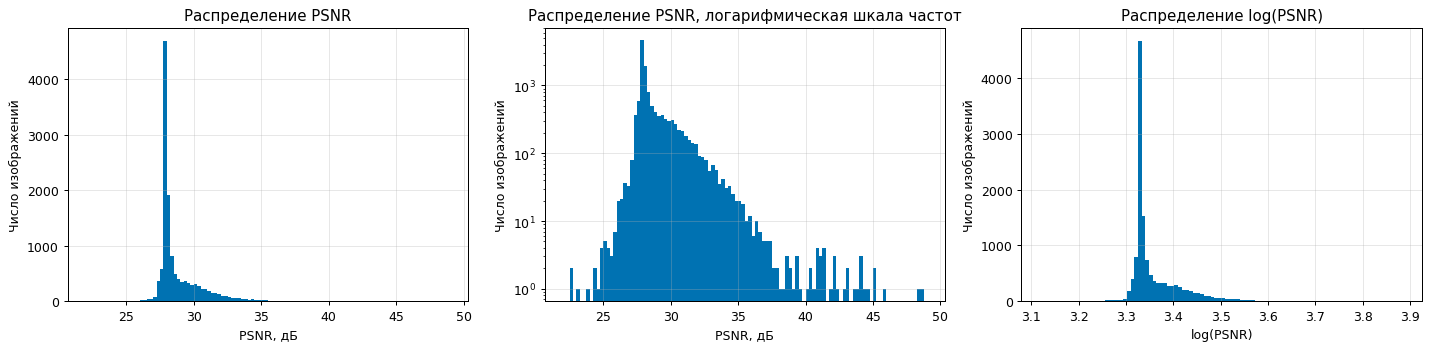

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bins = np.arange(np.floor(target.min()), np.ceil(target.max()) + 0.25, 0.25)
axes[0].hist(target, bins=bins)
axes[0].set(title="Распределение PSNR", xlabel="PSNR, дБ", ylabel="Число изображений")
axes[1].hist(target, bins=bins, log=True)
axes[1].set(title="Распределение PSNR, логарифмическая шкала частот", xlabel="PSNR, дБ",
            ylabel="Число изображений")
axes[2].hist(np.log(target), bins=100)
axes[2].set(title="Распределение log(PSNR)", xlabel="log(PSNR)", ylabel="Число изображений")
fig.tight_layout()

Для MAE лучшей константой является медиана, для MSE — среднее. Ниже обе константы оценены на всём train; оценка на фолдах приведена в README.

In [9]:
constants = {"среднее": target.mean(), "медиана": target.median()}
pd.DataFrame({
    "значение, дБ": constants,
    "MAE, дБ": {name: (target - value).abs().mean() for name, value in constants.items()},
})

,"значение, дБ","MAE, дБ"
среднее,28.84,1.228
медиана,28.06,1.026


In [10]:
median_error = (target - target.median()).abs()
top_share = target >= target.quantile(0.99)
pd.Series({
    "порог верхнего 1 %, дБ": target.quantile(0.99),
    "MAE медианы на верхнем 1 %": median_error[top_share].mean(),
    "MAE медианы на остальных": median_error[~top_share].mean(),
    "доля верхнего 1 % в суммарной ошибке": median_error[top_share].sum() / median_error.sum(),
}).rename("значение").to_frame()

,значение
"порог верхнего 1 %, дБ",35.22
MAE медианы на верхнем 1 %,10.07
MAE медианы на остальных,0.9339
доля верхнего 1 % в суммарной ошибке,0.09884


**Выводы.** Распределение PSNR сильно скошено вправо: асимметрия 2,9, эксцесс 14,4. Медиана равна 28,06 дБ, квартили — 27,89 и 29,30 дБ. 49 % изображений лежат в пределах ±0,25 дБ от медианы, а максимум достигает 48,74 дБ. Логарифм почти не уменьшает асимметрию: у log(PSNR) она равна 2,37. PSNR уже является логарифмом MSE, а форму распределения задаёт смесь вариантов искажения (раздел 3). Поэтому цель не преобразуется.

Для MAE лучшая константа — медиана: её ошибка 1,026 дБ против 1,228 дБ у среднего. Верхний 1 % значений (от 35,2 дБ) даёт 9,9 % суммарной ошибки медианы, средняя ошибка на нём 10,1 дБ. Функция потерь MSE заставит модель подстраиваться под этот хвост. Поэтому там, где модель это позволяет, предпочтительны функции потерь MAE или Huber.

## 3. Варианты искажения

По описанию соревнования данные получены искажением исходных изображений пятью способами: размытие по Гауссу, сжатие, линейное преобразование яркости и аддитивный гауссов шум, поканальный и в компоненте яркости. Какой номер варианта соответствует какому искажению, в данных не указано. Ниже это устанавливается по примерам и по тому, как меняются признаки.

Из определения PSNR можно восстановить среднеквадратичное отклонение от оригинала: $\mathrm{RMSE} = 255 \cdot 10^{-\mathrm{PSNR}/20}$. Для аддитивного гауссова шума с фиксированным $\sigma$ без обрезки значений $\mathrm{RMSE} \approx \sigma$, и PSNR почти не зависит от содержимого изображения.

In [11]:
train["rmse"] = 255 * 10 ** (-train[TARGET] / 20)
by_variant = train.groupby("variant").agg(
    изображений=(TARGET, "size"),
    среднее=(TARGET, "mean"),
    медиана=(TARGET, "median"),
    q25=(TARGET, lambda x: x.quantile(0.25)),
    q75=(TARGET, lambda x: x.quantile(0.75)),
    максимум=(TARGET, "max"),
    асимметрия=(TARGET, "skew"),
    rmse_медиана=("rmse", "median"),
    rmse_q25=("rmse", lambda x: x.quantile(0.25)),
    rmse_q75=("rmse", lambda x: x.quantile(0.75)),
)
by_variant

,изображений,среднее,медиана,q25,q75,максимум,асимметрия,rmse_медиана,rmse_q25,rmse_q75
variant,,,,,,,,,,
1,2642,29.65,29.23,28.2,30.52,42.16,1.495,8.81,7.599,9.925
2,2642,27.95,27.92,27.88,28.01,29.99,-4.318,10.25,10.14,10.29
3,2642,28.39,27.98,27.88,28.24,45.78,6.091,10.17,9.876,10.3
4,2642,28.29,27.9,27.64,28.24,48.74,4.839,10.27,9.88,10.58
5,2642,29.93,29.72,28.28,30.98,41.02,0.9928,8.325,7.205,9.824


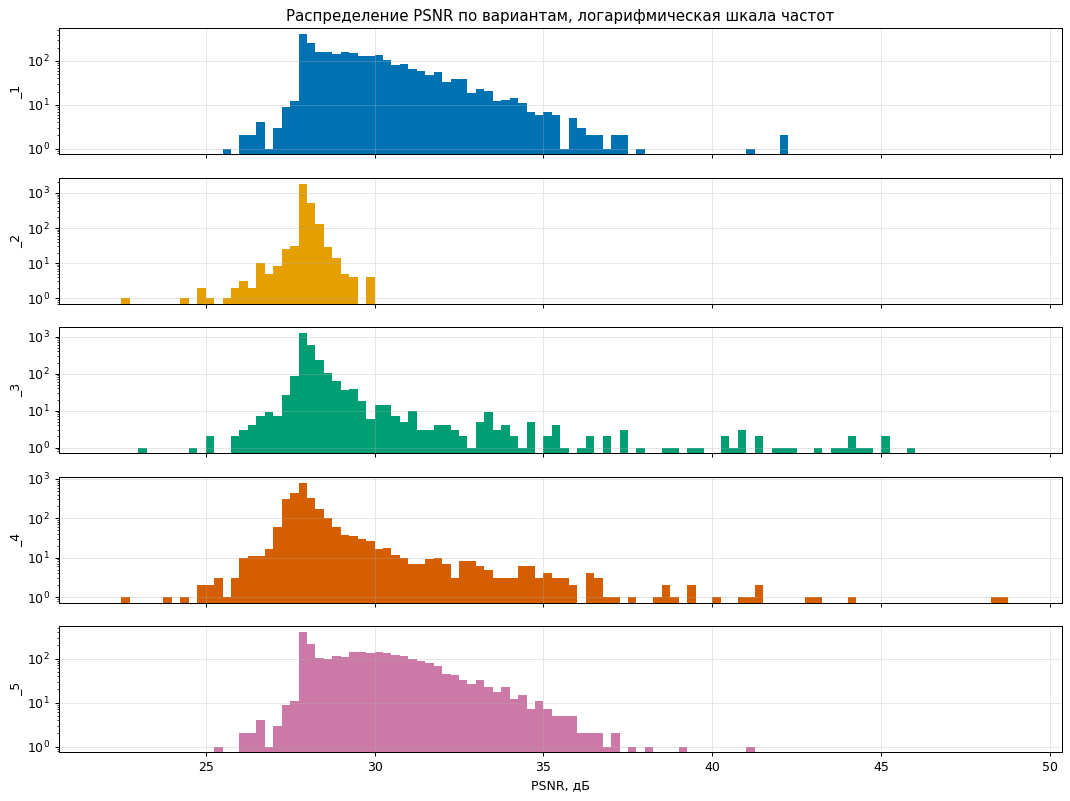

In [12]:
fig, axes = plt.subplots(len(VARIANTS), 1, figsize=(12, 9), sharex=True)
for axis, (variant, part) in zip(axes, train.groupby("variant")):
    axis.hist(part[TARGET], bins=bins, log=True, color=OKABE_ITO[int(variant) - 1])
    axis.set_ylabel(f"_{variant}")
axes[0].set_title("Распределение PSNR по вариантам, логарифмическая шкала частот")
axes[-1].set_xlabel("PSNR, дБ")
fig.tight_layout()

**Выводы.** У `_2` RMSE почти постоянна: медиана 10,25, квартили 10,14 и 10,29. Это соответствует шуму с σ ≈ 10,25 и PSNR около 27,9 дБ независимо от содержимого изображения. У `_3` и `_4` основная масса значений тоже сосредоточена у 27,9 дБ, но есть длинный хвост до 45,8 и 48,7 дБ. У `_1` и `_5` распределения широкие, квартили 28,2–30,5 и 28,3–31,0 дБ: ошибка размытия и сжатия зависит от количества мелких деталей на изображении. Узкий пик всего распределения PSNR образован вариантами `_2`, `_3` и `_4`, правый хвост — вариантами `_1` и `_5`, а также редкими значениями `_3` и `_4`.

### Пример одного исходника

Верхний ряд — изображения целиком, нижний — увеличенный фрагмент 64×64 пикселя.

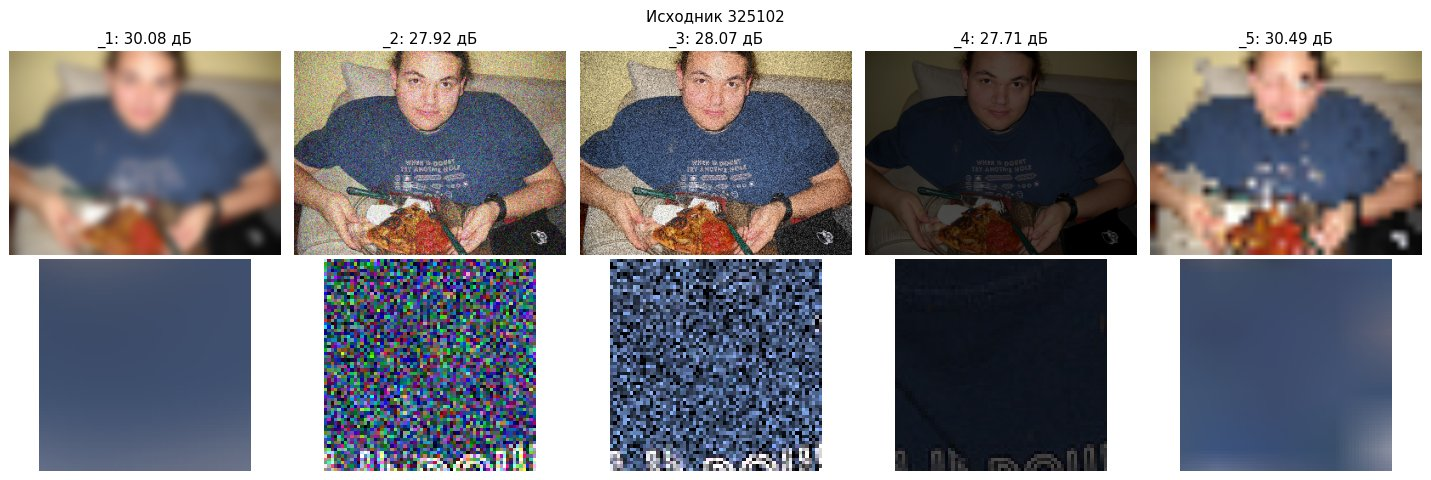

In [13]:
def show_source(source, crop=(200, 300), size=64):
    rows = train[train["source"] == source].sort_values("variant")
    fig, axes = plt.subplots(2, len(rows), figsize=(3.2 * len(rows), 5.4))
    top, left = crop
    for column, row in enumerate(rows.itertuples()):
        image = read_rgb(getattr(row, ID))
        axes[0, column].imshow(preview(getattr(row, ID)))
        axes[0, column].set_title(f"_{row.variant}: {getattr(row, TARGET):.2f} дБ")
        axes[1, column].imshow(image[top:top + size, left:left + size], interpolation="nearest")
        for axis in axes[:, column]:
            axis.axis("off")
    fig.suptitle(f"Исходник {source}")
    fig.tight_layout()
    show_photo(fig)


source_medians = train.groupby("source")[TARGET].median()
typical_source = (source_medians - source_medians.median()).abs().idxmin()
show_source(typical_source)

### Изменение признаков по вариантам

Чтобы убрать влияние содержимого, признак каждого варианта сравнивается со средним по остальным четырём вариантам того же исходника, разность делится на стандартное отклонение признака. На карте — медиана этой величины по исходникам: положительное значение означает, что у варианта признак выше, чем у других вариантов того же изображения.

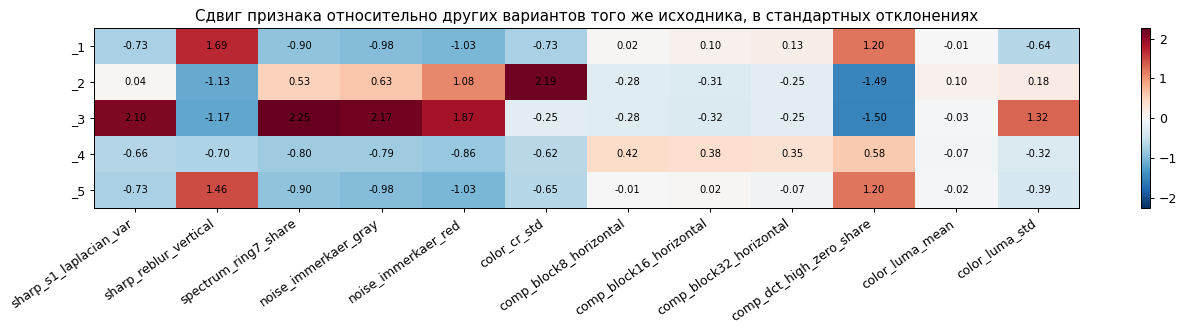

In [14]:
INDICATORS = [
    "sharp_s1_laplacian_var", "sharp_reblur_vertical", "spectrum_ring7_share",
    "noise_immerkaer_gray", "noise_immerkaer_red", "color_cr_std",
    "comp_block8_horizontal", "comp_block16_horizontal", "comp_block32_horizontal", "comp_dct_high_zero_share",
    "color_luma_mean", "color_luma_std",
]
indicators = train[INDICATORS]
others = (indicators.groupby(train["source"]).transform("sum") - indicators) / (len(VARIANTS) - 1)
shift = ((indicators - others) / indicators.std()).groupby(train["variant"]).median()

fig, axis = plt.subplots(figsize=(15, 3.8))
limit = shift.abs().to_numpy().max()
image = axis.imshow(shift, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
axis.set_xticks(range(len(INDICATORS)), INDICATORS, rotation=35, ha="right")
axis.set_yticks(range(len(VARIANTS)), [f"_{v}" for v in VARIANTS])
for (i, j), value in np.ndenumerate(shift.to_numpy()):
    axis.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
axis.grid(False)
axis.set_title("Сдвиг признака относительно других вариантов того же исходника, в стандартных отклонениях")
fig.colorbar(image, ax=axis)
fig.tight_layout()

**Выводы.** По примеру и по сдвигу признаков варианты соответствуют следующим искажениям.

| Вариант | Искажение | Что видно по признакам |
|---|---|---|
| `_1` | размытие по Гауссу | резкость, энергия высоких частот и оценка шума ниже, чем у других вариантов; растут устойчивость к повторному размытию и доля нулевых высокочастотных коэффициентов DCT |
| `_2` | гауссов шум в каждом цветовом канале | наибольший рост цветового шума `color_cr_std` |
| `_3` | гауссов шум в компоненте яркости | наибольший рост шума, резкости и контраста яркости без роста цветового шума |
| `_4` | линейное преобразование яркости | на примере изображение темнее; по признакам немного снижен контраст, остальные признаки близки к средним |
| `_5` | сжатие | на примере видны крупные однородные блоки; по признакам вариант почти совпадает с размытием, блочность на сетках 8, 16 и 32 пикселя не растёт |

Сходство признаков `_1` и `_5` означает, что модель плохо различает эти два искажения, хотя оба уничтожают мелкие детали.

### Связь вариантов одного исходника

Если PSNR разных вариантов одного исходника согласованы, их уровень определяется содержимым изображения. Это и есть информация, которую модель должна извлечь из пикселей.

,count,mean,std,min,50%,90%,99%,max
"размах, дБ",2642,2.775,2.628,0.006266,2.356,5.922,12.98,20.84


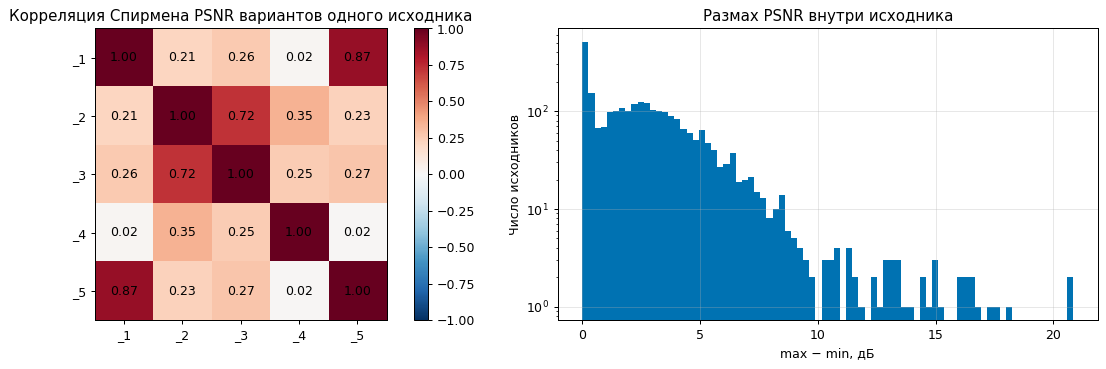

In [15]:
by_source = train.pivot(index="source", columns="variant", values=TARGET)
source_corr = by_source.corr(method="spearman")
spread = by_source.max(axis=1) - by_source.min(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
image = axes[0].imshow(source_corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(VARIANTS)), [f"_{v}" for v in VARIANTS])
axes[0].set_yticks(range(len(VARIANTS)), [f"_{v}" for v in VARIANTS])
for (i, j), value in np.ndenumerate(source_corr.to_numpy()):
    axes[0].text(j, i, f"{value:.2f}", ha="center", va="center")
axes[0].grid(False)
axes[0].set_title("Корреляция Спирмена PSNR вариантов одного исходника")
fig.colorbar(image, ax=axes[0])
axes[1].hist(spread, bins=80, log=True)
axes[1].set(title="Размах PSNR внутри исходника", xlabel="max − min, дБ", ylabel="Число исходников")
fig.tight_layout()
spread.describe(percentiles=[0.5, 0.9, 0.99]).rename("размах, дБ").to_frame().T

**Выводы.** PSNR вариантов `_1` и `_5` одного исходника сильно согласованы (ρ = 0,87), шумовых `_2` и `_3` — умеренно (0,72), остальные пары связаны слабо (не более 0,35). Значит, уровень PSNR при размытии и сжатии задаётся одним свойством содержимого — количеством мелких деталей, которые сглаживают оба искажения. Размах PSNR внутри исходника имеет медиану 2,36 дБ, 99-й процентиль 12,98 дБ и максимум 20,84 дБ. Варианты одного исходника выглядят похоже, а значения цели у них заметно различаются.

### Изображения с наибольшим PSNR

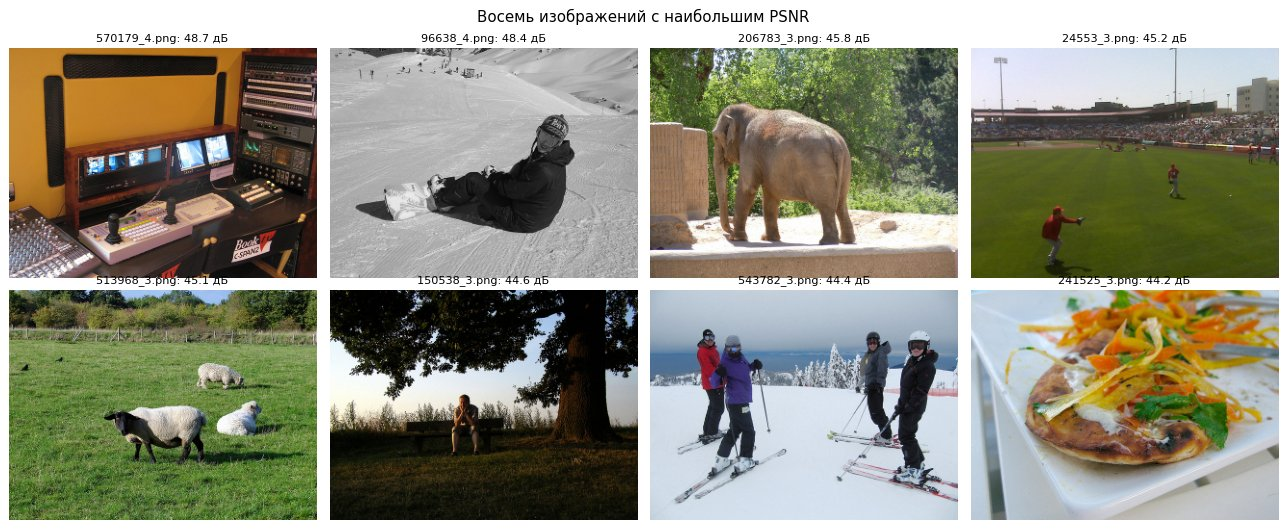

In [16]:
def show_images(rows, title, columns=4):
    fig, axes = plt.subplots(int(np.ceil(len(rows) / columns)), columns, figsize=(3.6 * columns, 6))
    for axis, row in zip(axes.flat, rows.itertuples()):
        axis.imshow(preview(getattr(row, ID)))
        axis.set_title(f"{getattr(row, ID)}: {getattr(row, TARGET):.1f} дБ", fontsize=9)
    for axis in axes.flat:
        axis.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    show_photo(fig)


show_images(train.nlargest(8, TARGET), "Восемь изображений с наибольшим PSNR")

In [17]:
top = train[top_share]
pd.DataFrame({
    "доля в верхнем 1 %": top["variant"].value_counts(normalize=True),
    "доля в train": train["variant"].value_counts(normalize=True),
}).fillna(0).sort_index()

,доля в верхнем 1 %,доля в train
variant,,
1,0.218,0.2
2,0,0.2
3,0.2932,0.2
4,0.2632,0.2
5,0.2256,0.2


In [18]:
compare = ["color_luma_std", "color_share_zero", "color_share_full", "sharp_s1_flat_share", "sharp_s1_laplacian_var"]
pd.DataFrame({
    "верхний 1 %": top[compare].median(),
    "остальные": train.loc[~top_share, compare].median(),
})

,верхний 1 %,остальные
color_luma_std,55.07,61.15
color_share_zero,0.000102,0.003308
color_share_full,5.1e-05,0.01163
sharp_s1_flat_share,0.02609,0.03292
sharp_s1_laplacian_var,379.4,1206


**Выводы.** В верхний 1 % PSNR попадают варианты `_3` (29 %), `_4` (26 %), `_5` (23 %) и `_1` (22 %), но не `_2`. На изображениях с наибольшим PSNR искажение визуально незаметно, хотя основная масса тех же вариантов имеет PSNR около 28 дБ. У таких изображений меньше насыщенных пикселей: медианная доля пикселей с максимальным значением 0,005 % против 1,2 %. Дисперсия лапласиана у них ниже (379 против 1206), то есть мелких деталей меньше. На почти неискажённых изображениях модель будет ошибаться сильнее всего.

## 4. Распределения признаков

Признаки разбиты на группы по способу расчёта. Ниже для каждой группы приведены число признаков, асимметрия, доля выбросов по правилу Тьюки (значения дальше 1,5 межквартильного размаха от квартилей) и разброс масштабов.

In [19]:
skew = values.skew()
q1, q3 = values.quantile(0.25), values.quantile(0.75)
iqr = q3 - q1
outlier_share = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).mean()
std = values.std()
pd.DataFrame({
    "признаков": GROUPS.value_counts(),
    "медиана |асимметрии|": skew.abs().groupby(GROUPS).median(),
    "доля с |асимметрией| > 2": (skew.abs() > 2).groupby(GROUPS).mean(),
    "средняя доля выбросов": outlier_share.groupby(GROUPS).mean(),
    "мин. ст. отклонение": std.groupby(GROUPS).min(),
    "макс. ст. отклонение": std.groupby(GROUPS).max(),
}).sort_values("признаков", ascending=False)

,признаков,медиана |асимметрии|,доля с |асимметрией| > 2,средняя доля выбросов,мин. ст. отклонение,макс. ст. отклонение
color,35,1.127,0.4,0.0477,0.08159,67.63
texture,34,0.6876,0.1765,0.01783,0.01497,503.3
sharp,23,1.134,0.2174,0.04457,0.06621,5.578e+04
nss,16,0.3134,0,0.02833,0.05988,2.817
comp,14,2.148,0.5714,0.06116,0.01952,22.42
noise,10,0.8537,0,0.00836,0.2104,84.53
spectrum,9,1.176,0,0.02714,0.01964,1.232


In [20]:
print(f"Отношение наибольшего и наименьшего стандартного отклонения: {std.max() / std.min():.3g}")
rows_with_extremes = ((values < q1 - 3 * iqr) | (values > q3 + 3 * iqr)).any(axis=1).mean()
print(f"Доля изображений хотя бы с одним значением дальше 3 IQR: {rows_with_extremes:.1%}")

Отношение наибольшего и наименьшего стандартного отклонения: 3.73e+06
Доля изображений хотя бы с одним значением дальше 3 IQR: 37.1%


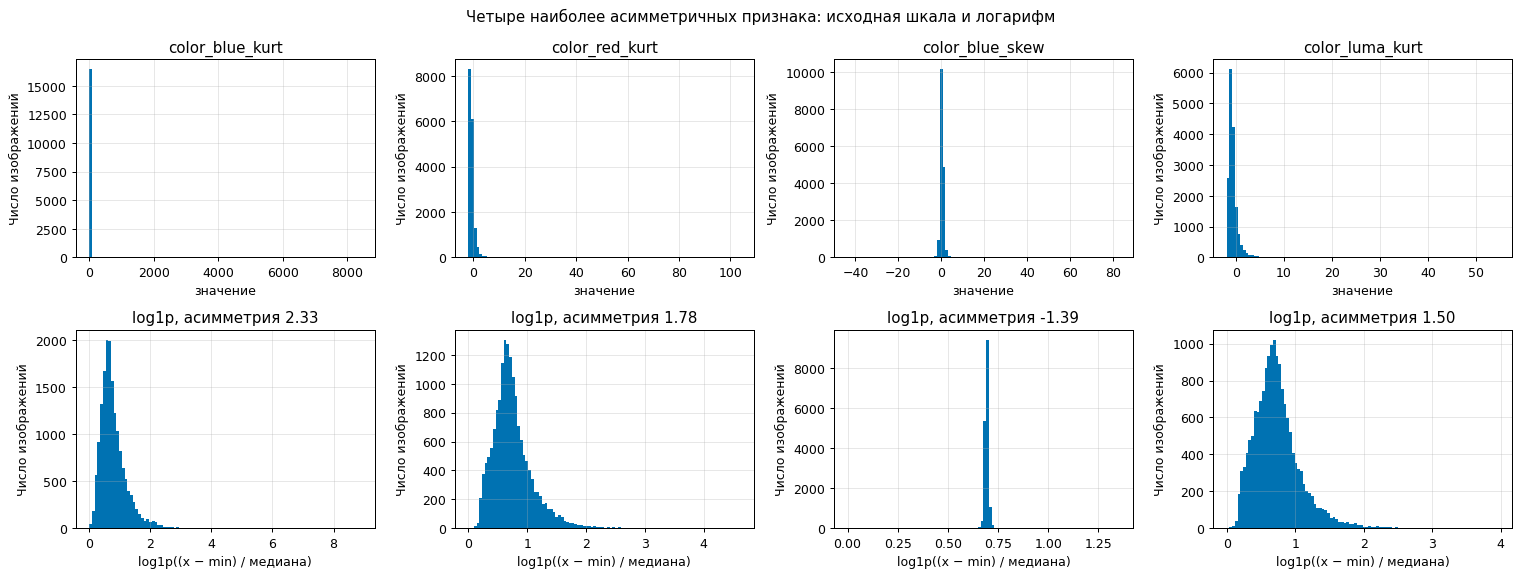

In [21]:
most_skewed = skew.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for column, name in enumerate(most_skewed):
    axes[0, column].hist(values[name], bins=100)
    axes[0, column].set(title=name, xlabel="значение", ylabel="Число изображений")
    shifted = values[name] - values[name].min()
    axes[1, column].hist(np.log1p(shifted / shifted.median()), bins=100)
    axes[1, column].set(title=f"log1p, асимметрия {np.log1p(shifted / shifted.median()).skew():.2f}",
                        xlabel="log1p((x − min) / медиана)", ylabel="Число изображений")
fig.suptitle("Четыре наиболее асимметричных признака: исходная шкала и логарифм")
fig.tight_layout()

**Выводы.** Масштабы признаков различаются на шесть порядков: отношение наибольшего стандартного отклонения к наименьшему равно 3,7·10⁶. Для линейных моделей, KNN и нейросети признаки необходимо масштабировать, деревья и бустинги к масштабу нечувствительны.

Многие распределения скошены: модуль асимметрии больше 2 у 57 % признаков группы `comp` и у 40 % группы `color`. Логарифм выравнивает признаки вроде эксцесса. Знаковым величинам вроде `color_blue_skew` он не помогает: их основная масса значений сосредоточена в узком интервале. Поэтому на этапе предобработки сравниваются стандартизация, `RobustScaler` и квантильное преобразование.

Выбросы по правилу Тьюки составляют в среднем от 0,8 до 6,1 % значений признака в зависимости от группы. У 37,1 % изображений хотя бы одно значение лежит дальше трёх межквартильных размахов от квартилей. Удаление таких строк лишило бы модель более трети данных, а выбросы здесь отражают свойства изображений, а не ошибки измерения. Поэтому строки не удаляются, а ограничение значений квантилями обучающей части проверяется на этапе предобработки.

## 5. Связь признаков с PSNR

Используется корреляция Спирмена: она учитывает любую монотонную связь и устойчива к выбросам и асимметрии, в отличие от корреляции Пирсона.

Наибольшая |ρ| Спирмена: 0.534, Пирсона: 0.437
Признаков с | |ρ_S| − |ρ_P| | > 0,1: 67


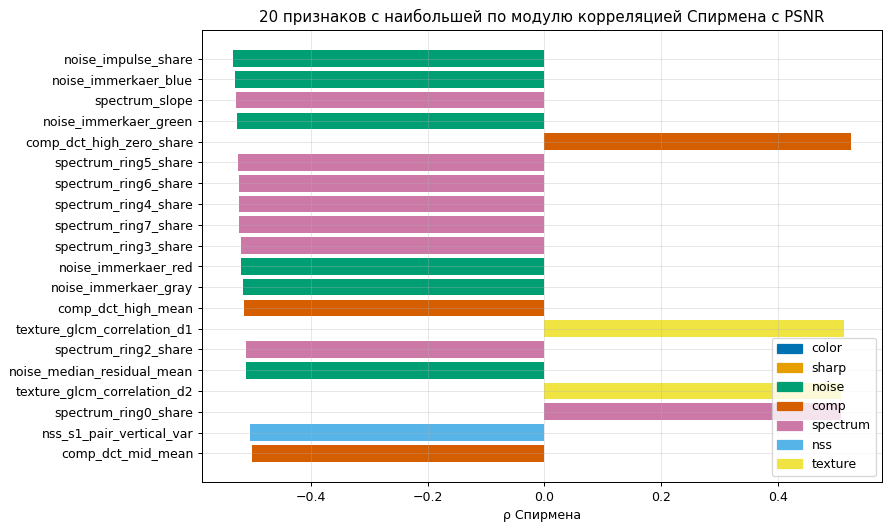

In [22]:
spearman = train[FEATURES].corrwith(train[TARGET], method="spearman")
pearson = train[FEATURES].corrwith(train[TARGET])
strongest = spearman.abs().sort_values(ascending=False).index[:20]
group_colors = dict(zip(GROUPS.unique(), OKABE_ITO))

fig, axis = plt.subplots(figsize=(10, 6))
axis.barh(strongest[::-1], spearman[strongest[::-1]], color=[group_colors[GROUPS[n]] for n in strongest[::-1]])
axis.set(title="20 признаков с наибольшей по модулю корреляцией Спирмена с PSNR", xlabel="ρ Спирмена")
axis.legend(handles=[Patch(color=color, label=group) for group, color in group_colors.items()],
            loc="lower right")
fig.tight_layout()

print(f"Наибольшая |ρ| Спирмена: {spearman.abs().max():.3f}, Пирсона: {pearson.abs().max():.3f}")
print(f"Признаков с | |ρ_S| − |ρ_P| | > 0,1: {((spearman.abs() - pearson.abs()).abs() > 0.1).sum()}")

Общая корреляция смешивает два эффекта: различие вариантов искажения и различие изображений внутри одного варианта. Модель не знает номер варианта, но для `_1` и `_5` ей нужно уметь оценивать PSNR внутри варианта. Поэтому ниже корреляции посчитаны отдельно для каждого варианта, по группам признаков взят наибольший модуль.

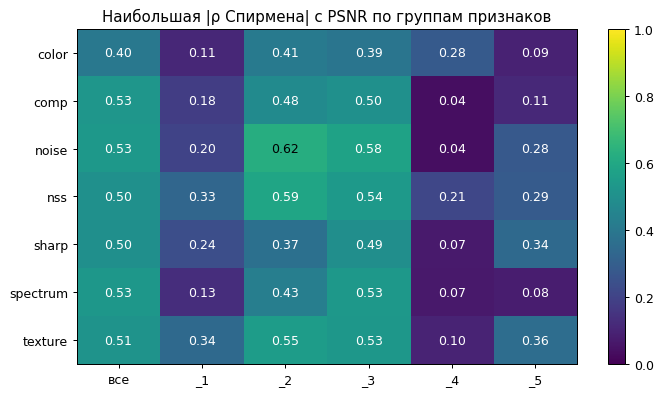

In [23]:
within = pd.DataFrame({
    f"_{variant}": part[FEATURES].corrwith(part[TARGET], method="spearman")
    for variant, part in train.groupby("variant")
})
within.insert(0, "все", spearman)
best_within = within.abs().groupby(GROUPS).max()

fig, axis = plt.subplots(figsize=(8, 4.5))
image = axis.imshow(best_within, cmap="viridis", vmin=0, vmax=1, aspect="auto")
axis.set_xticks(range(best_within.shape[1]), best_within.columns)
axis.set_yticks(range(best_within.shape[0]), best_within.index)
for (i, j), value in np.ndenumerate(best_within.to_numpy()):
    axis.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if value < 0.6 else "black")
axis.grid(False)
axis.set_title("Наибольшая |ρ Спирмена| с PSNR по группам признаков")
fig.colorbar(image, ax=axis)
fig.tight_layout()

In [24]:
within.abs().idxmax().rename("признак").to_frame().join(within.abs().max().rename("|ρ|"))

,признак,|ρ|
все,noise_impulse_share,0.5339
_1,texture_lbp_5,0.3407
_2,noise_block_std_p05,0.6223
_3,noise_impulse_share,0.576
_4,color_green_skew,0.2848
_5,texture_lbp_4,0.3559


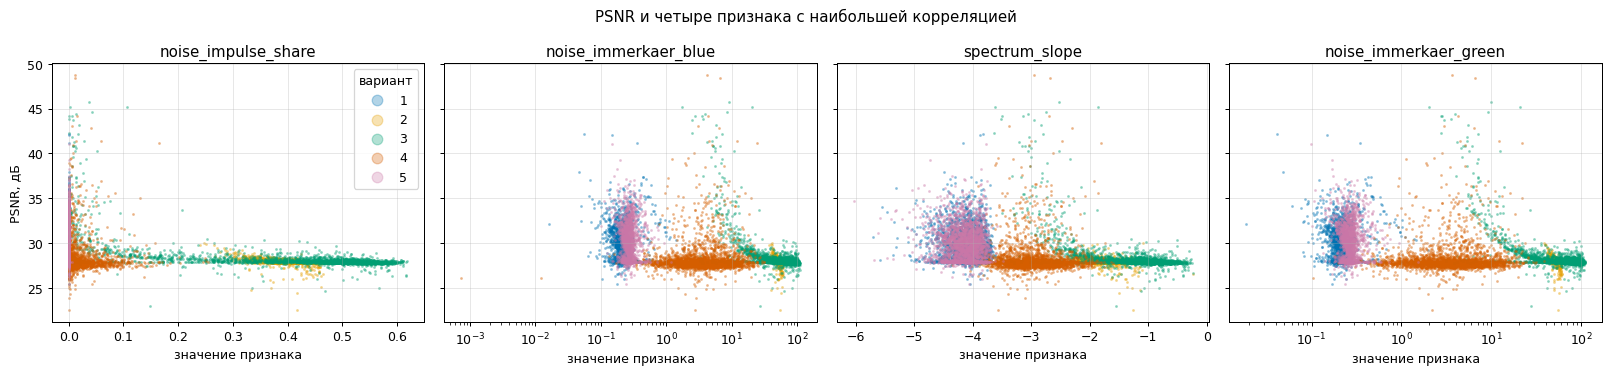

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for axis, name in zip(axes, strongest[:4]):
    for variant, part in train.groupby("variant"):
        axis.scatter(part[name], part[TARGET], s=2, alpha=0.3, label=variant)
    if (train[name] > 0).all() and train[name].max() / train[name].min() > 100:
        axis.set_xscale("log")
    axis.set(title=name, xlabel="значение признака")
axes[0].set_ylabel("PSNR, дБ")
axes[0].legend(markerscale=6, title="вариант")
fig.suptitle("PSNR и четыре признака с наибольшей корреляцией")
fig.tight_layout()

**Выводы.** Ни один признак не определяет PSNR: наибольшая |ρ| Спирмена равна 0,53 (`noise_impulse_share`). Среди сильнейших признаков преобладают оценки шума и энергии высоких частот. У 67 признаков корреляции Спирмена и Пирсона различаются по модулю больше чем на 0,1. Связь с целью монотонная, но нелинейная, и это видно на диаграммах рассеяния. Это ограничивает линейные модели без преобразования признаков.

Внутри вариантов картина разная. Для `_2` и `_3` есть признаки с |ρ| 0,62 и 0,58, а для `_1`, `_5` и `_4` наибольшая |ρ| равна 0,34, 0,36 и 0,28. Варианты `_1` и `_5` имеют самый широкий разброс PSNR и при этом хуже всего описываются признаками, поэтому на них придётся основная ошибка моделей. На этапе feature engineering нужны признаки, которые оценивают потерю мелких деталей при размытии и сжатии.

## 6. Корреляции между признаками

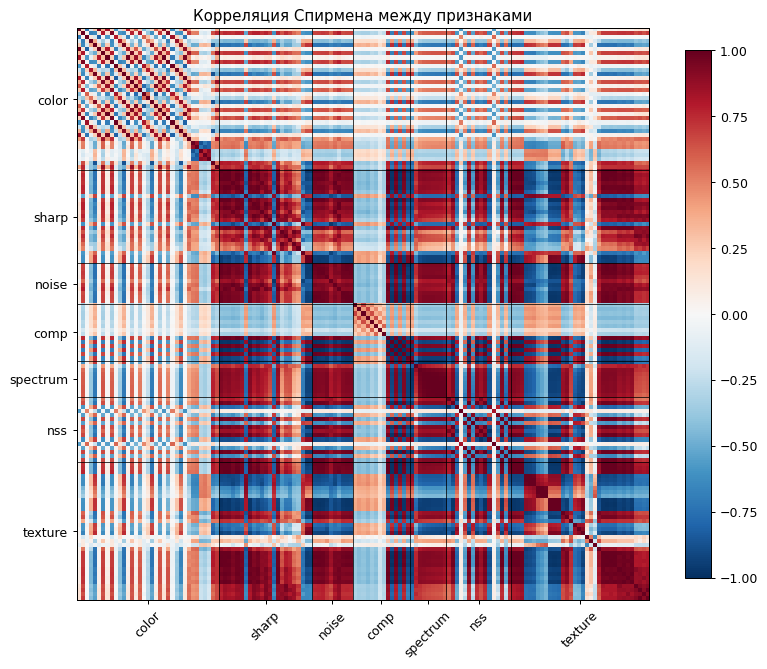

In [26]:
feature_corr = train[FEATURES].corr(method="spearman")

fig, axis = plt.subplots(figsize=(9, 8))
image = axis.imshow(feature_corr, cmap="RdBu_r", vmin=-1, vmax=1)
borders = np.flatnonzero(GROUPS.to_numpy()[1:] != GROUPS.to_numpy()[:-1]) + 0.5
for border in borders:
    axis.axhline(border, color="black", linewidth=0.6)
    axis.axvline(border, color="black", linewidth=0.6)
starts = np.r_[0, borders + 0.5]
ends = np.r_[borders + 0.5, len(FEATURES)]
axis.set_xticks((starts + ends) / 2 - 0.5, GROUPS.unique(), rotation=45)
axis.set_yticks((starts + ends) / 2 - 0.5, GROUPS.unique())
axis.grid(False)
axis.set_title("Корреляция Спирмена между признаками")
fig.colorbar(image, ax=axis, shrink=0.8)
fig.tight_layout()

In [27]:
upper = feature_corr.abs().where(np.triu(np.ones(feature_corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
clusters = {}
for threshold in (0.9, 0.95, 0.99):
    n_clusters, _ = connected_components(feature_corr.abs().to_numpy() > threshold, directed=False)
    clusters[threshold] = {"пар выше порога": int((pairs > threshold).sum()), "кластеров признаков": n_clusters}
pd.DataFrame(clusters).T.rename_axis("порог |ρ|")

,пар выше порога,кластеров признаков
порог |ρ|,,
0.9,1589,37
0.95,822,60
0.99,94,104


In [28]:
pairs.head(10).rename("|ρ|").to_frame()

,,|ρ|
noise_immerkaer_gray,comp_dct_high_mean,0.9993
nss_s2_pair_horizontal_var,nss_s2_pair_vertical_var,0.9993
nss_s1_pair_horizontal_var,nss_s1_pair_vertical_var,0.999
spectrum_ring6_share,spectrum_ring7_share,0.9988
texture_gabor_w4_o1,texture_gabor_w4_o3,0.9986
texture_glcm_correlation_d1,texture_glcm_correlation_d2,0.9986
nss_s2_var,nss_s2_pair_vertical_var,0.9985
sharp_s1_laplacian_var,comp_dct_mid_mean,0.9984
spectrum_ring5_share,spectrum_ring6_share,0.9984
nss_s2_var,nss_s2_pair_horizontal_var,0.9984


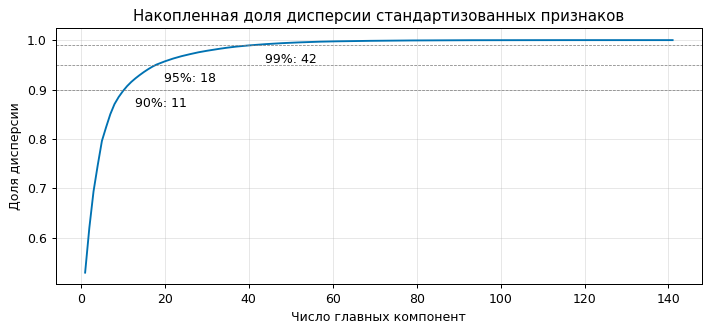

In [29]:
pca = PCA().fit(StandardScaler().fit_transform(train[FEATURES]))
explained = np.cumsum(pca.explained_variance_ratio_)
fig, axis = plt.subplots(figsize=(8, 3.8))
axis.plot(np.arange(1, len(explained) + 1), explained)
for level in (0.9, 0.95, 0.99):
    count = int(np.searchsorted(explained, level) + 1)
    axis.axhline(level, color="grey", linewidth=0.6, linestyle="--")
    axis.annotate(f"{level:.0%}: {count}", (count, level), textcoords="offset points", xytext=(6, -14))
axis.set(title="Накопленная доля дисперсии стандартизованных признаков", xlabel="Число главных компонент",
         ylabel="Доля дисперсии")
fig.tight_layout()

**Выводы.** Признаки сильно избыточны: у 822 пар |ρ| больше 0,95, у 94 пар — больше 0,99. При пороге 0,95 141 признак объединяется в 60 групп связанных признаков. Первые 11 главных компонент объясняют 90 % дисперсии стандартизованных признаков, 18 — 95 %, 42 — 99 %. Для линейной регрессии без регуляризации это означает мультиколлинеарность и неустойчивые коэффициенты, поэтому нужны Ridge, Lasso или ElasticNet. На этапе предобработки проверяются удаление одного признака из каждой пары с |ρ| больше 0,95 и PCA.

## 7. Сравнение train и test

Для каждого признака считается статистика Колмогорова–Смирнова — наибольшая разница эмпирических функций распределения в train и test. Затем выполняется adversarial validation: классификатор учится отличать изображения test от train. ROC AUC около 0,5 означает, что выборки по признакам неразличимы. Фолды группируются по исходнику, иначе классификатор узнавал бы исходник по его вариантам.

In [30]:
ks = pd.DataFrame(
    [stats.ks_2samp(train[name], test[name]) for name in FEATURES],
    index=FEATURES, columns=["статистика", "p"],
)
ks["p с поправкой Бонферрони"] = np.minimum(ks["p"] * len(FEATURES), 1)
print("Признаков с p < 0,05 после поправки:", (ks["p с поправкой Бонферрони"] < 0.05).sum())
ks.sort_values("статистика", ascending=False).head(5)

Признаков с p < 0,05 после поправки: 0


,статистика,p,p с поправкой Бонферрони
color_cb_std,0.03113,0.01159,1
color_red_mean,0.02438,0.08466,1
color_red_p50,0.02405,0.09207,1
comp_block8_horizontal,0.02322,0.1133,1
color_green_kurt,0.02315,0.1155,1


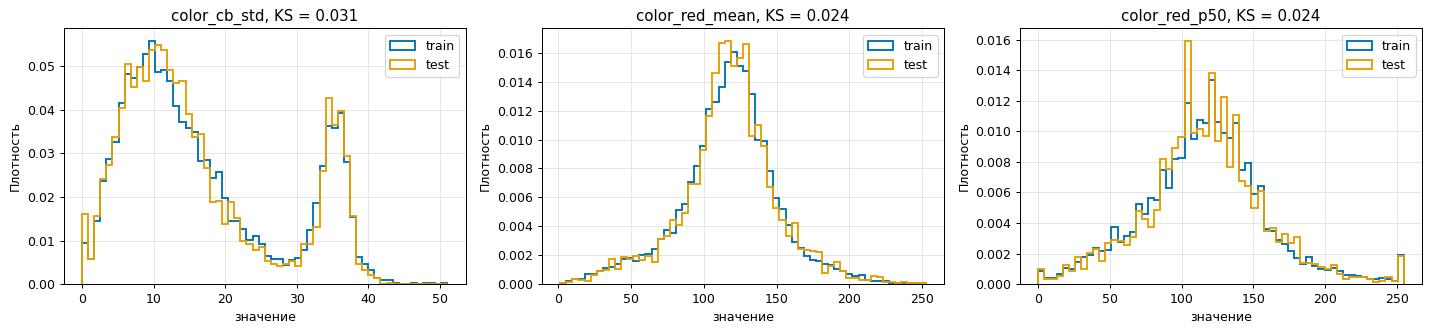

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for axis, name in zip(axes, ks["статистика"].nlargest(3).index):
    edges = np.histogram_bin_edges(both[name], bins=60)
    axis.hist(train[name], bins=edges, density=True, histtype="step", linewidth=1.5, label="train")
    axis.hist(test[name], bins=edges, density=True, histtype="step", linewidth=1.5, label="test")
    axis.set(title=f"{name}, KS = {ks.loc[name, 'статистика']:.3f}", xlabel="значение", ylabel="Плотность")
    axis.legend()
fig.tight_layout()

In [32]:
is_test = (both["part"] == "test").to_numpy()
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
proba = cross_val_predict(
    HistGradientBoostingClassifier(random_state=SEED), both[FEATURES], is_test,
    cv=splitter, groups=both["source"], method="predict_proba",
)[:, 1]
print(f"Adversarial validation, ROC AUC: {roc_auc_score(is_test, proba):.3f}")

Adversarial validation, ROC AUC: 0.502


**Выводы.** Распределения признаков в train и test совпадают. Наибольшая статистика Колмогорова–Смирнова равна 0,031, и после поправки на множественные сравнения ни одно различие не значимо. Классификатор не отличает test от train: ROC AUC 0,502. Поэтому оценка на фолдах train должна переноситься на test. Это согласуется с результатом медианы: 1,026 дБ на фолдах и 0,994–1,006 дБ на Kaggle.

## 8. Проверка разбиения на фолды

В проекте используется `StratifiedGroupKFold`: 5 фолдов, стратификация по 10 квантильным бинам PSNR, группа — исходник.

In [33]:
folds = make_folds(train, TARGET, **config["validation"])
fold_of = np.empty(len(train), dtype=int)
for number, (_, valid_index) in enumerate(folds):
    fold_of[valid_index] = number
train["fold"] = fold_of
assert train.groupby("source")["fold"].nunique().eq(1).all()

train.groupby("fold").agg(
    изображений=(TARGET, "size"),
    исходников=("source", "nunique"),
    среднее=(TARGET, "mean"),
    медиана=(TARGET, "median"),
    p99=(TARGET, lambda x: x.quantile(0.99)),
    максимум=(TARGET, "max"),
)

,изображений,исходников,среднее,медиана,p99,максимум
fold,,,,,,
0,2640,528,28.82,28.08,34.62,48.41
1,2645,529,28.86,28.05,35.08,44.17
2,2645,529,28.82,28.05,35.13,45.78
3,2640,528,28.85,28.05,35.29,48.74
4,2640,528,28.86,28.08,35.57,45.14


**Выводы.** Каждый исходник целиком попадает в один фолд. В каждом фолде 2 640–2 645 изображений и 528–529 исходников, медианы PSNR 28,05–28,08 дБ, 99-е процентили 34,6–35,6 дБ: стратификация по бинам PSNR выравнивает фолды. Максимумы различаются сильнее, от 44,2 до 48,7 дБ: крайних значений единицы, и они увеличивают разброс ошибки между фолдами.

## 9. Повторы содержимого под разными исходниками

Группировка по исходнику защищает от утечки, только если одно и то же изображение не встречается под разными номерами исходника. Для проверки каждый исходник представлен уменьшенной до 32×32 копией варианта `_4` в оттенках серого: линейное преобразование яркости сохраняет структуру изображения, а корреляция к нему нечувствительна. Для каждой пары исходников считается наибольшая корреляция Пирсона между миниатюрами по восьми положениям второй из них: четыре поворота на 90° с отражением и без него.

,исходников с парой выше порога
0.8,307
0.85,155
0.9,34
0.95,2
0.98,2
0.99,2


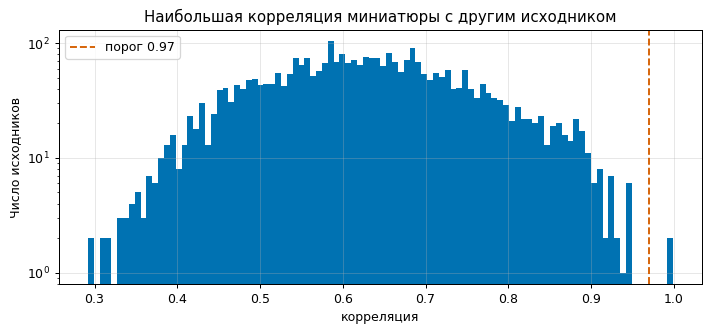

In [34]:
THUMB = 32
DUPLICATE = 0.97


def thumbnail(name):
    gray = cv2.cvtColor(read_rgb(name), cv2.COLOR_RGB2GRAY)
    return cv2.resize(gray, (THUMB, THUMB), interpolation=cv2.INTER_AREA).astype(np.float32)


def normalize(stack):
    flat = stack.reshape(len(stack), -1)
    flat = flat - flat.mean(axis=1, keepdims=True)
    return flat / np.maximum(np.linalg.norm(flat, axis=1, keepdims=True), 1e-6)


reference = both[both["variant"] == "4"].reset_index(drop=True)
thumbs = np.stack([thumbnail(name) for name in reference[ID]])
base = normalize(thumbs)
similarity = np.full((len(thumbs), len(thumbs)), -1.0, dtype=np.float32)
for mirrored in (thumbs, thumbs[:, :, ::-1]):
    for turns in range(4):
        np.maximum(similarity, base @ normalize(np.rot90(mirrored, turns, axes=(1, 2))).T, out=similarity)
np.fill_diagonal(similarity, -1)
best = similarity.max(axis=1)

fig, axis = plt.subplots(figsize=(8, 3.8))
axis.hist(best, bins=100, log=True)
axis.set(title="Наибольшая корреляция миниатюры с другим исходником", xlabel="корреляция",
         ylabel="Число исходников")
axis.axvline(DUPLICATE, color=OKABE_ITO[3], linestyle="--", label=f"порог {DUPLICATE}")
axis.legend()
fig.tight_layout()
pd.Series({threshold: int((best > threshold).sum()) for threshold in (0.8, 0.85, 0.9, 0.95, 0.98, 0.99)},
          name="исходников с парой выше порога").to_frame()

In [35]:
first, second = np.nonzero(np.triu(similarity, k=1) > 0.9)
pairs = pd.DataFrame({
    "первый": reference.loc[first, ID].to_numpy(),
    "второй": reference.loc[second, ID].to_numpy(),
    "корреляция": similarity[first, second],
    "части": reference.loc[first, "part"].to_numpy() + "–" + reference.loc[second, "part"].to_numpy(),
}).sort_values("корреляция", ascending=False, ignore_index=True)
pairs.head(5)

,первый,второй,корреляция,части
0,465129_4.png,535889_4.png,0.9987,train–test
1,203171_4.png,275015_4.png,0.9479,train–train
2,429369_4.png,518530_4.png,0.9448,train–train
3,119120_4.png,231644_4.png,0.9446,train–test
4,429369_4.png,482062_4.png,0.9361,train–train


При поиске ближайших соседей в пространстве стандартизованных признаков найдена ещё одна пара: `551987` в train и `402077` в test. Это тот же снимок, повёрнутый на 90° и иначе кадрированный. Из-за другого кадрирования миниатюры совпадают плохо.

Корреляция миниатюр пары 551987–402077: 0.529


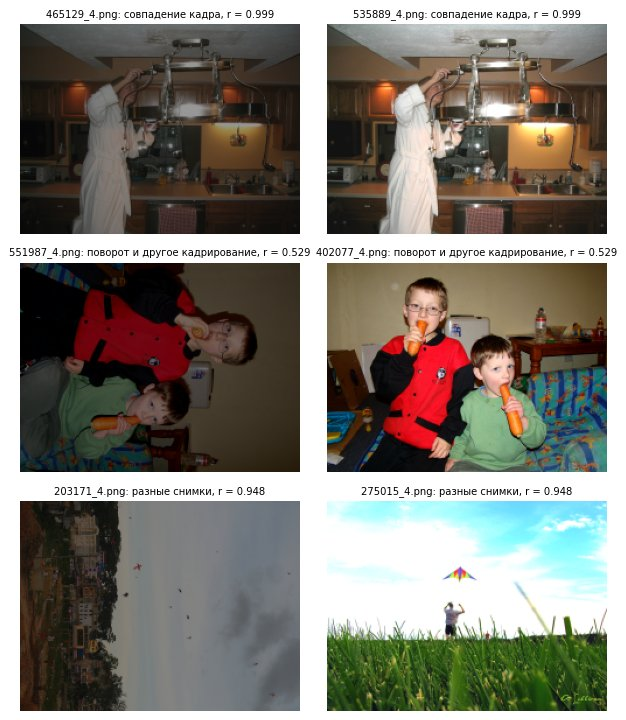

In [36]:
position = dict(zip(reference["source"], reference.index))
rotated = ("551987", "402077")
print(f"Корреляция миниатюр пары {rotated[0]}–{rotated[1]}: {similarity[position[rotated[0]], position[rotated[1]]]:.3f}")

shown = [tuple(pairs.loc[0, ["первый", "второй"]]), tuple(f"{source}_4.png" for source in rotated),
         tuple(pairs.loc[1, ["первый", "второй"]])]
captions = ["совпадение кадра", "поворот и другое кадрирование", "разные снимки"]
fig, axes = plt.subplots(len(shown), 2, figsize=(7, 2.7 * len(shown)))
for row, pair, caption in zip(axes, shown, captions):
    r = similarity[position[pair[0].split("_")[0]], position[pair[1].split("_")[0]]]
    for axis, name in zip(row, pair):
        axis.imshow(preview(name, 240))
        axis.set_title(f"{name}: {caption}, r = {r:.3f}", fontsize=8)
        axis.axis("off")
fig.tight_layout()
show_photo(fig)

**Выводы.** Совпадение кадра найдено для одной пары исходников: `465129` в train и `535889` в test, r = 0,999. Следующая по сходству пара имеет r = 0,948 и состоит из разных снимков, поэтому порог 0,97 отделяет повторы от случайного сходства. Метод находит только совпадение всего кадра: пара `551987`–`402077`, где снимок повёрнут и иначе кадрирован, получает r = 0,529. Поэтому найденное число повторов — нижняя оценка. Обе известные пары связывают train и test, а внутри train совпадений кадра не найдено. Поэтому группировка фолдов по исходнику остаётся без изменений.

## Итоги

1. Пропусков, бесконечных значений, повторяющихся строк и постоянных признаков нет: заполнение и удаление не требуются.
2. Категориальных признаков на входе модели нет. Номер варианта используется только для группировки и разбивки ошибки.
3. Масштабы признаков различаются на шесть порядков: для линейных моделей, KNN и MLP признаки масштабируются. Сравниваются стандартизация, `RobustScaler` и квантильное преобразование. Преобразования обучаются только на обучающей части фолда.
4. Строки с выбросами не удаляются, так как это более трети данных. Проверяется ограничение значений квантилями обучающей части.
5. Признаки сильно коррелированы: для линейных моделей нужна регуляризация. Сравниваются отбор признаков по порогу |ρ| > 0,95 и PCA.
6. Цель не преобразуется. Лучшая константа — медиана, функции потерь MAE и Huber предпочтительнее MSE.
7. Валидация: `StratifiedGroupKFold` с группировкой по исходнику. Train и test однородны, поэтому локальная оценка представительна.
8. Основной резерв качества — признаки для вариантов `_1` и `_5`, где связь существующих признаков с PSNR слабая.